# Dự đoán khách huỷ đặt phòng khách sạn

**Dữ liệu:** [Hotel Reservations Dataset (Kaggle)](https://www.kaggle.com/datasets/ahsan81/hotel-reservations-classification-dataset), gồm 36.275 lượt đặt phòng và 19 cột.

**Bài toán:** phân loại nhị phân. Từ thông tin có tại thời điểm đặt phòng, dự đoán `booking_status` là `Canceled` (huỷ) hay `Not_Canceled` (không huỷ).

**Ý nghĩa thực tế:** đặt phòng online làm tỷ lệ huỷ và không đến tăng cao. Nếu biết sớm booking nào dễ bị huỷ, khách sạn có thể nhắc khách, yêu cầu đặt cọc, hoặc bán vượt (overbooking) có kiểm soát để giảm số phòng bị bỏ trống.

**Nội dung**
1. Đọc dữ liệu & tổng quan
2. Kiểm tra chất lượng dữ liệu
3. Phân tích khám phá (EDA)
4. Tạo đặc trưng
5. Chiến lược đánh giá: xử lý **dòng trùng lặp**, nguyên nhân khiến nhiều notebook báo accuracy cao hơn thực tế
6. So sánh mô hình: Logistic Regression, Random Forest, XGBoost, LightGBM
7. Tinh chỉnh siêu tham số
8. Chọn ngưỡng phân loại
9. Đánh giá trên tập test
10. Mức độ quan trọng của đặc trưng
11. Kết luận & khuyến nghị

| Cột | Ý nghĩa |
|---|---|
| `Booking_ID` | Mã đặt phòng |
| `no_of_adults`, `no_of_children` | Số người lớn / trẻ em |
| `no_of_weekend_nights`, `no_of_week_nights` | Số đêm cuối tuần (T7, CN) / trong tuần (T2–T6) |
| `type_of_meal_plan` | Gói ăn uống khách chọn |
| `required_car_parking_space` | Có cần chỗ đậu xe hay không (0/1) |
| `room_type_reserved` | Loại phòng (đã được mã hoá) |
| `lead_time` | Số ngày từ lúc đặt phòng đến ngày nhận phòng |
| `arrival_year`, `arrival_month`, `arrival_date` | Năm, tháng, ngày nhận phòng |
| `market_segment_type` | Phân khúc thị trường / kênh đặt phòng |
| `repeated_guest` | Khách quay lại (0/1) |
| `no_of_previous_cancellations` | Số lần khách đã huỷ trước đó |
| `no_of_previous_bookings_not_canceled` | Số lần khách đã đặt trước đó mà không huỷ |
| `avg_price_per_room` | Giá trung bình mỗi đêm (euro), thay đổi theo ngày |
| `no_of_special_requests` | Số yêu cầu đặc biệt (tầng cao, view đẹp…) |
| `booking_status` | **Biến mục tiêu**: `Canceled` / `Not_Canceled` |

## 0. Thiết lập

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import loguniform, randint, uniform

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, average_precision_score,
                             classification_report, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedGroupKFold, StratifiedKFold,
                                     cross_val_predict, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)

# Chạy được cả trên máy cá nhân lẫn trên Kaggle
DATA_CANDIDATES = [
    Path("data/Hotel Reservations.csv"),
    Path("/kaggle/input/hotel-reservations-classification-dataset/Hotel Reservations.csv"),
]
DATA_PATH = next(p for p in DATA_CANDIDATES if p.exists())

In [2]:
# Màu thống nhất cho toàn notebook: xanh = không huỷ, cam = huỷ
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
STATUS_COLORS = {"Not_Canceled": BLUE, "Canceled": ORANGE}
STATUS_LABELS = {"Not_Canceled": "Không huỷ", "Canceled": "Huỷ"}
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#104281"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "text.color": INK, "legend.frameon": False, "font.size": 10, "figure.dpi": 110,
})

## 1. Đọc dữ liệu & tổng quan

In [3]:
df_raw = pd.read_csv(DATA_PATH)
print(f"{df_raw.shape[0]:,} dòng × {df_raw.shape[1]} cột")
df_raw.head()

36,275 dòng × 19 cột


,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN00001,2,0,1,2,Meal Plan 1,0,Room_Type 1,224,2017,10,2,Offline,0,0,0,65.00,0,Not_Canceled
1,INN00002,2,0,2,3,Not Selected,0,Room_Type 1,5,2018,11,6,Online,0,0,0,106.68,1,Not_Canceled
2,INN00003,1,0,2,1,Meal Plan 1,0,Room_Type 1,1,2018,2,28,Online,0,0,0,60.00,0,Canceled
3,INN00004,2,0,0,2,Meal Plan 1,0,Room_Type 1,211,2018,5,20,Online,0,0,0,100.00,0,Canceled
4,INN00005,2,0,1,1,Not Selected,0,Room_Type 1,48,2018,4,11,Online,0,0,0,94.50,0,Canceled


In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 36275 entries, 0 to 36274
Data columns (total 19 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Booking_ID                            36275 non-null  str    
 1   no_of_adults                          36275 non-null  int64  
 2   no_of_children                        36275 non-null  int64  
 3   no_of_weekend_nights                  36275 non-null  int64  
 4   no_of_week_nights                     36275 non-null  int64  
 5   type_of_meal_plan                     36275 non-null  str    
 6   required_car_parking_space            36275 non-null  int64  
 7   room_type_reserved                    36275 non-null  str    
 8   lead_time                             36275 non-null  int64  
 9   arrival_year                          36275 non-null  int64  
 10  arrival_month                         36275 non-null  int64  
 11  arrival_date              

In [5]:
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
no_of_adults,36275.0,1.84,0.52,0.0,2.0,2.00,2.0,4.0
no_of_children,36275.0,0.11,0.40,0.0,0.0,0.00,0.0,10.0
no_of_weekend_nights,36275.0,0.81,0.87,0.0,0.0,1.00,2.0,7.0
no_of_week_nights,36275.0,2.20,1.41,0.0,1.0,2.00,3.0,17.0
required_car_parking_space,36275.0,0.03,0.17,0.0,0.0,0.00,0.0,1.0
lead_time,36275.0,85.23,85.93,0.0,17.0,57.00,126.0,443.0
arrival_year,36275.0,2017.82,0.38,2017.0,2018.0,2018.00,2018.0,2018.0
arrival_month,36275.0,7.42,3.07,1.0,5.0,8.00,10.0,12.0
arrival_date,36275.0,15.60,8.74,1.0,8.0,16.00,23.0,31.0
repeated_guest,36275.0,0.03,0.16,0.0,0.0,0.00,0.0,1.0


## 2. Kiểm tra chất lượng dữ liệu

In [6]:
FEATURE_COLS = df_raw.columns.drop(["Booking_ID", "booking_status"]).tolist()

print("Số ô bị thiếu:", df_raw.isna().sum().sum())
print("Booking_ID bị trùng:", df_raw["Booking_ID"].duplicated().sum())

dup_any = df_raw.duplicated(subset=FEATURE_COLS, keep=False)
dup_extra = df_raw.duplicated(subset=FEATURE_COLS)
print(f"Dòng có ít nhất 1 bản sao giống hệt (bỏ qua Booking_ID): {dup_any.sum():,} ({dup_any.mean():.1%})")
print(f"Dòng thừa nếu mỗi nhóm trùng chỉ giữ 1 bản:            {dup_extra.sum():,} ({dup_extra.mean():.1%})")

n_labels = df_raw[dup_any].groupby(FEATURE_COLS)["booking_status"].nunique()
print(f"Nhóm trùng lặp có nhãn mâu thuẫn (vừa huỷ vừa không): {(n_labels > 1).sum()} / {len(n_labels):,}")

Số ô bị thiếu: 0
Booking_ID bị trùng: 0
Dòng có ít nhất 1 bản sao giống hệt (bỏ qua Booking_ID): 13,568 (37.4%)
Dòng thừa nếu mỗi nhóm trùng chỉ giữ 1 bản:            10,408 (28.7%)
Nhóm trùng lặp có nhãn mâu thuẫn (vừa huỷ vừa không): 133 / 3,160


In [7]:
# Ví dụ: nhóm trùng lặp lớn nhất
row_key = pd.util.hash_pandas_object(df_raw[FEATURE_COLS], index=False)
top_key = row_key.value_counts().index[0]
print(f"Nhóm trùng lớn nhất có {(row_key == top_key).sum()} dòng giống hệt nhau, ví dụ:")
df_raw[row_key == top_key].head()

Nhóm trùng lớn nhất có 95 dòng giống hệt nhau, ví dụ:


,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
245,INN00246,1,0,0,2,Meal Plan 1,0,Room_Type 1,164,2017,10,2,Offline,0,0,0,100.0,0,Not_Canceled
770,INN00771,1,0,0,2,Meal Plan 1,0,Room_Type 1,164,2017,10,2,Offline,0,0,0,100.0,0,Not_Canceled
977,INN00978,1,0,0,2,Meal Plan 1,0,Room_Type 1,164,2017,10,2,Offline,0,0,0,100.0,0,Not_Canceled
1139,INN01140,1,0,0,2,Meal Plan 1,0,Room_Type 1,164,2017,10,2,Offline,0,0,0,100.0,0,Not_Canceled
1244,INN01245,1,0,0,2,Meal Plan 1,0,Room_Type 1,164,2017,10,2,Offline,0,0,0,100.0,0,Not_Canceled


**Nhận xét về dòng trùng lặp.** 37,4% số dòng (13.568) có ít nhất một bản sao giống hệt ở mọi cột trừ `Booking_ID`. Nếu mỗi nhóm chỉ giữ một bản thì thừa ra 10.408 dòng (28,7%). Nhóm lớn nhất gồm 95 booking cùng ngày nhận phòng, cùng lead time, cùng giá, cùng kênh *Offline*. Nhiều khả năng đây là **booking theo đoàn** (công ty du lịch giữ nhiều phòng một lúc) chứ không phải lỗi nhập liệu. Chỉ 133/3.160 nhóm có nhãn mâu thuẫn, nghĩa là các phòng trong cùng một đoàn gần như luôn cùng bị huỷ hoặc cùng được giữ. Điều này ảnh hưởng trực tiếp đến cách chia train/test (mục 5).

In [8]:
arrival = pd.to_datetime(
    dict(year=df_raw["arrival_year"], month=df_raw["arrival_month"], day=df_raw["arrival_date"]),
    errors="coerce",
)
print("Ngày nhận phòng không hợp lệ:", arrival.isna().sum())
df_raw.loc[arrival.isna(), ["arrival_year", "arrival_month", "arrival_date"]].value_counts()

Ngày nhận phòng không hợp lệ: 37


arrival_year  arrival_month  arrival_date
2018          2              29              37
Name: count, dtype: int64

In [9]:
total_nights = df_raw["no_of_weekend_nights"] + df_raw["no_of_week_nights"]
pd.Series({
    "Giá phòng = 0": (df_raw["avg_price_per_room"] == 0).sum(),
    "Không có người lớn (chỉ trẻ em)": (df_raw["no_of_adults"] == 0).sum(),
    "Tổng số đêm = 0": (total_nights == 0).sum(),
    "Số trẻ em ≥ 9": (df_raw["no_of_children"] >= 9).sum(),
}, name="Số dòng").to_frame()

,Số dòng
Giá phòng = 0,545
Không có người lớn (chỉ trẻ em),139
Tổng số đêm = 0,78
Số trẻ em ≥ 9,3


In [10]:
# Các booking giá 0 thuộc phân khúc nào?
df_raw.loc[df_raw["avg_price_per_room"] == 0, "market_segment_type"].value_counts()

market_segment_type
Complementary    354
Online           191
Name: count, dtype: int64

**Quyết định xử lý**
- **Ngày 29/02/2018 (37 dòng):** năm 2018 không nhuận nên đây là lỗi dữ liệu. Loại bỏ 37 dòng này (0,1%).
- **Giá phòng = 0 (545 dòng):** 354 dòng thuộc phân khúc *Complementary* (phòng tặng), 191 dòng thuộc *Online* (nhiều khả năng là khuyến mãi). Hợp lý nên giữ nguyên.
- **Không có người lớn (139), 0 đêm (78, khách thuê trong ngày), 9–10 trẻ em (3):** hiếm nhưng có thể xảy ra. Giữ nguyên vì mô hình dạng cây không nhạy với giá trị ngoại lai.
- **Dòng trùng lặp:** giữ nguyên, nhưng xử lý ở bước chia dữ liệu khi đánh giá (mục 5).

In [11]:
df = (
    df_raw.assign(arrival=arrival)
    .loc[arrival.notna()]
    .drop(columns="Booking_ID")
    .reset_index(drop=True)
)
print(f"Sau khi làm sạch: {len(df):,} dòng")

Sau khi làm sạch: 36,238 dòng


## 3. Phân tích khám phá (EDA)

### 3.1 Biến mục tiêu

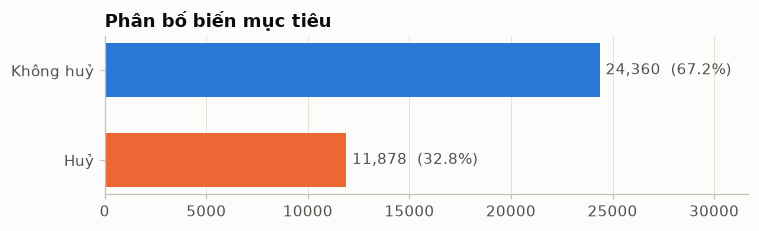

In [12]:
counts = df["booking_status"].value_counts().reindex(["Not_Canceled", "Canceled"])

fig, ax = plt.subplots(figsize=(7, 2.2))
bars = ax.barh([STATUS_LABELS[s] for s in counts.index], counts.values,
               color=[STATUS_COLORS[s] for s in counts.index], height=0.6)
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_width() + 300, bar.get_y() + bar.get_height() / 2,
            f"{n:,}  ({n / counts.sum():.1%})", va="center", color=INK_2)
ax.set_xlim(0, counts.max() * 1.3)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_title("Phân bố biến mục tiêu")
plt.tight_layout()
plt.show()

Dữ liệu **mất cân bằng nhẹ**: khoảng 1/3 số booking bị huỷ. Một mô hình luôn đoán "không huỷ" đã đạt accuracy 67%, nên ngoài accuracy cần theo dõi thêm **F1 của lớp Huỷ** và **ROC-AUC**.

### 3.2 Lead time và giá phòng

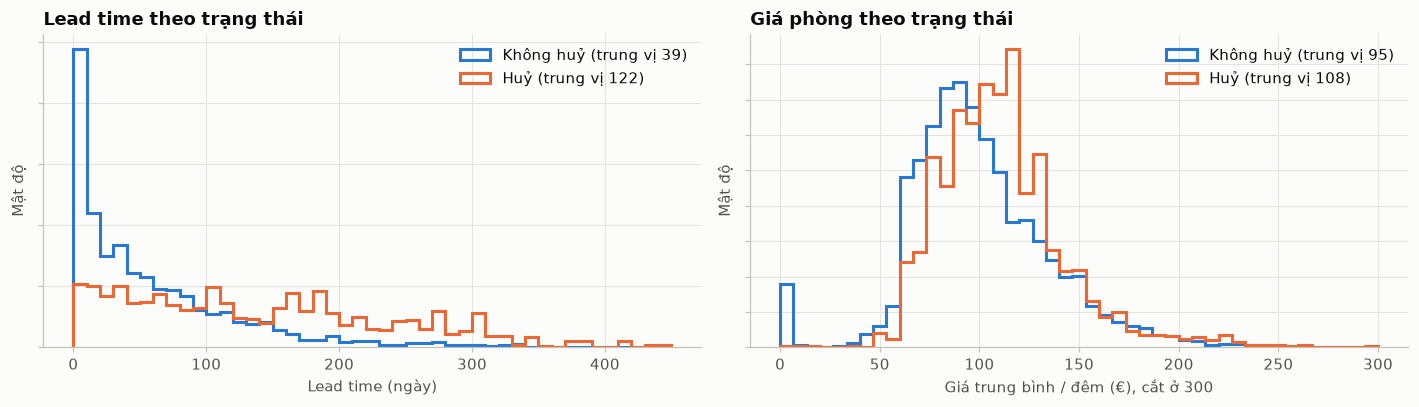

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
specs = [
    ("lead_time", "Lead time (ngày)", np.linspace(0, 450, 46)),
    ("avg_price_per_room", "Giá trung bình / đêm (€), cắt ở 300", np.linspace(0, 300, 46)),
]
for ax, (col, label, bins) in zip(axes, specs):
    for status in ["Not_Canceled", "Canceled"]:
        values = df.loc[df["booking_status"] == status, col]
        ax.hist(values, bins=bins, density=True, histtype="step", linewidth=2,
                color=STATUS_COLORS[status], label=f"{STATUS_LABELS[status]} (trung vị {values.median():.0f})")
    ax.set_xlabel(label)
    ax.set_ylabel("Mật độ")
    ax.yaxis.set_major_formatter(mtick.NullFormatter())
    ax.legend()
axes[0].set_title("Lead time theo trạng thái")
axes[1].set_title("Giá phòng theo trạng thái")
plt.tight_layout()
plt.show()

### 3.3 Tỷ lệ huỷ theo các biến phân loại

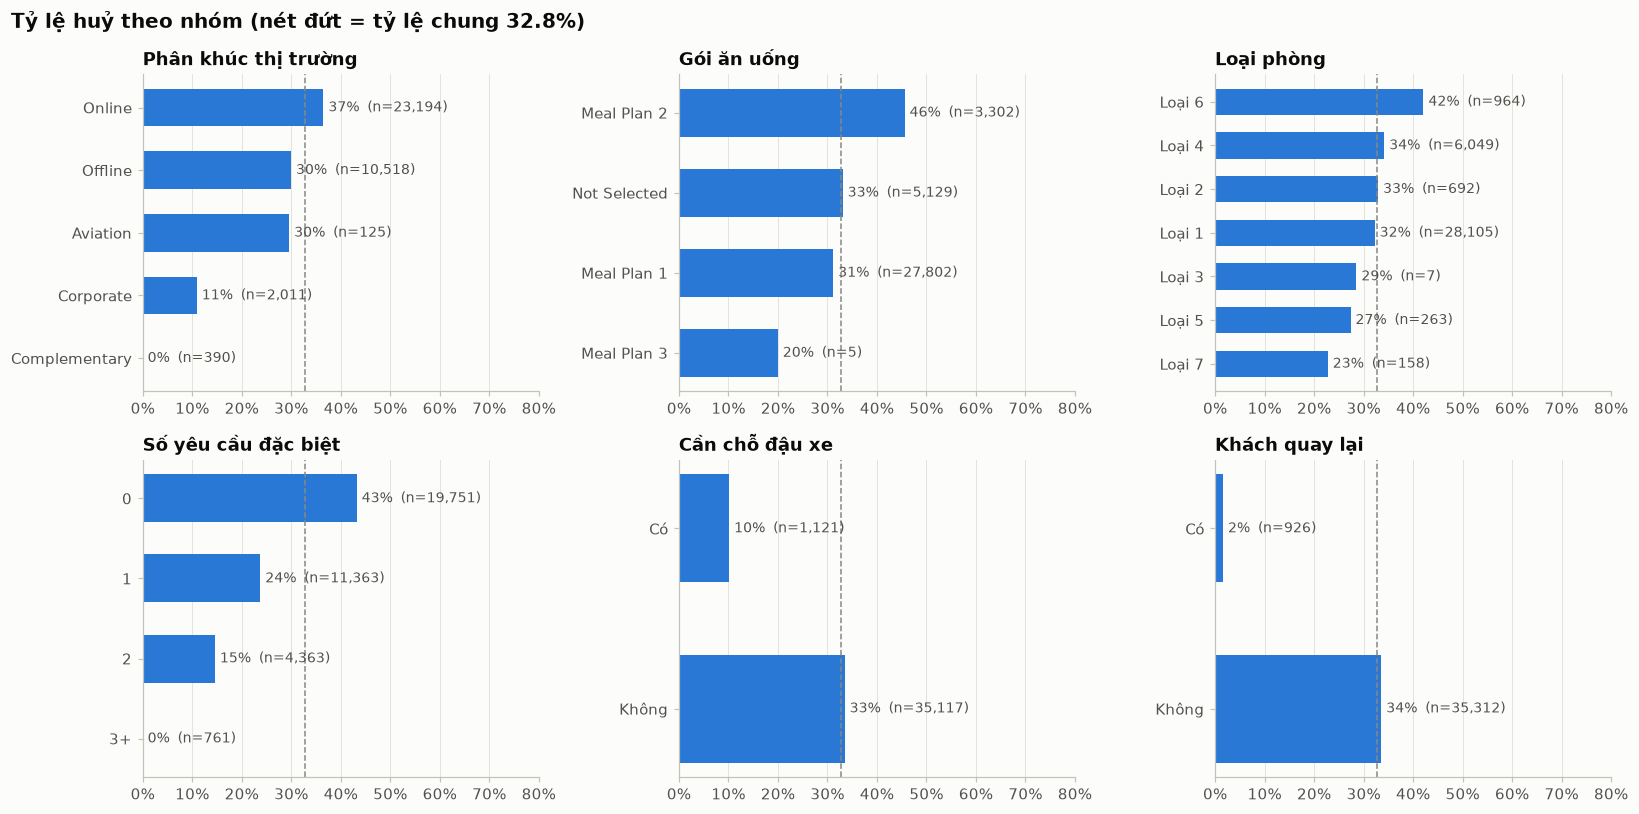

In [14]:
is_cancel = df["booking_status"].eq("Canceled")
overall_rate = is_cancel.mean()

panels = [  # (tiêu đề, dữ liệu, có sắp xếp theo tỷ lệ không)
    ("Phân khúc thị trường", df["market_segment_type"], True),
    ("Gói ăn uống", df["type_of_meal_plan"], True),
    ("Loại phòng", df["room_type_reserved"].str.replace("Room_Type ", "Loại "), True),
    ("Số yêu cầu đặc biệt", df["no_of_special_requests"].clip(upper=3).astype(str).replace("3", "3+"), False),
    ("Cần chỗ đậu xe", df["required_car_parking_space"].map({0: "Không", 1: "Có"}), False),
    ("Khách quay lại", df["repeated_guest"].map({0: "Không", 1: "Có"}), False),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, (title, series, sort) in zip(axes.flat, panels):
    stats = is_cancel.groupby(series).agg(rate="mean", n="size")
    if sort:
        stats = stats.sort_values("rate", ascending=False)
    pos = np.arange(len(stats))
    ax.barh(pos, stats["rate"], color=BLUE, height=0.6)
    ax.set_yticks(pos, stats.index)
    ax.invert_yaxis()
    ax.axvline(overall_rate, color=MUTED, linestyle="--", linewidth=1)
    for p, (rate, n) in zip(pos, stats.itertuples(index=False)):
        ax.text(rate + 0.01, p, f"{rate:.0%}  (n={n:,})", va="center", fontsize=9, color=INK_2)
    ax.set_xlim(0, 0.8)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
fig.suptitle(f"Tỷ lệ huỷ theo nhóm (nét đứt = tỷ lệ chung {overall_rate:.1%})",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

### 3.4 Tỷ lệ huỷ theo lead time

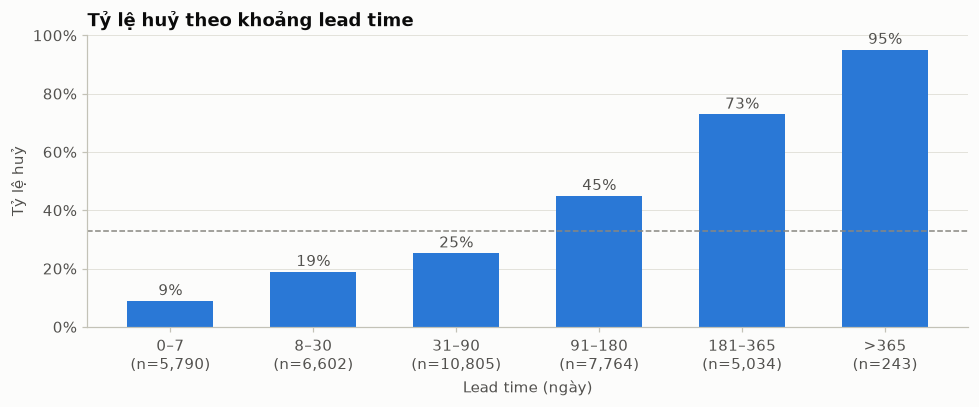

In [15]:
lead_bins = [-1, 7, 30, 90, 180, 365, np.inf]
lead_labels = ["0–7", "8–30", "31–90", "91–180", "181–365", ">365"]
lead_group = pd.cut(df["lead_time"], bins=lead_bins, labels=lead_labels)
stats = is_cancel.groupby(lead_group, observed=True).agg(rate="mean", n="size")

fig, ax = plt.subplots(figsize=(9, 3.8))
xlabels = [f"{label}\n(n={n:,})" for label, n in zip(stats.index, stats["n"])]
bars = ax.bar(xlabels, stats["rate"], color=BLUE, width=0.6)
for bar, rate in zip(bars, stats["rate"]):
    ax.text(bar.get_x() + bar.get_width() / 2, rate + 0.02, f"{rate:.0%}", ha="center", color=INK_2)
ax.axhline(overall_rate, color=MUTED, linestyle="--", linewidth=1)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Lead time (ngày)")
ax.set_ylabel("Tỷ lệ huỷ")
ax.grid(axis="x", visible=False)
ax.set_title("Tỷ lệ huỷ theo khoảng lead time")
plt.tight_layout()
plt.show()

### 3.5 Theo thời gian nhận phòng

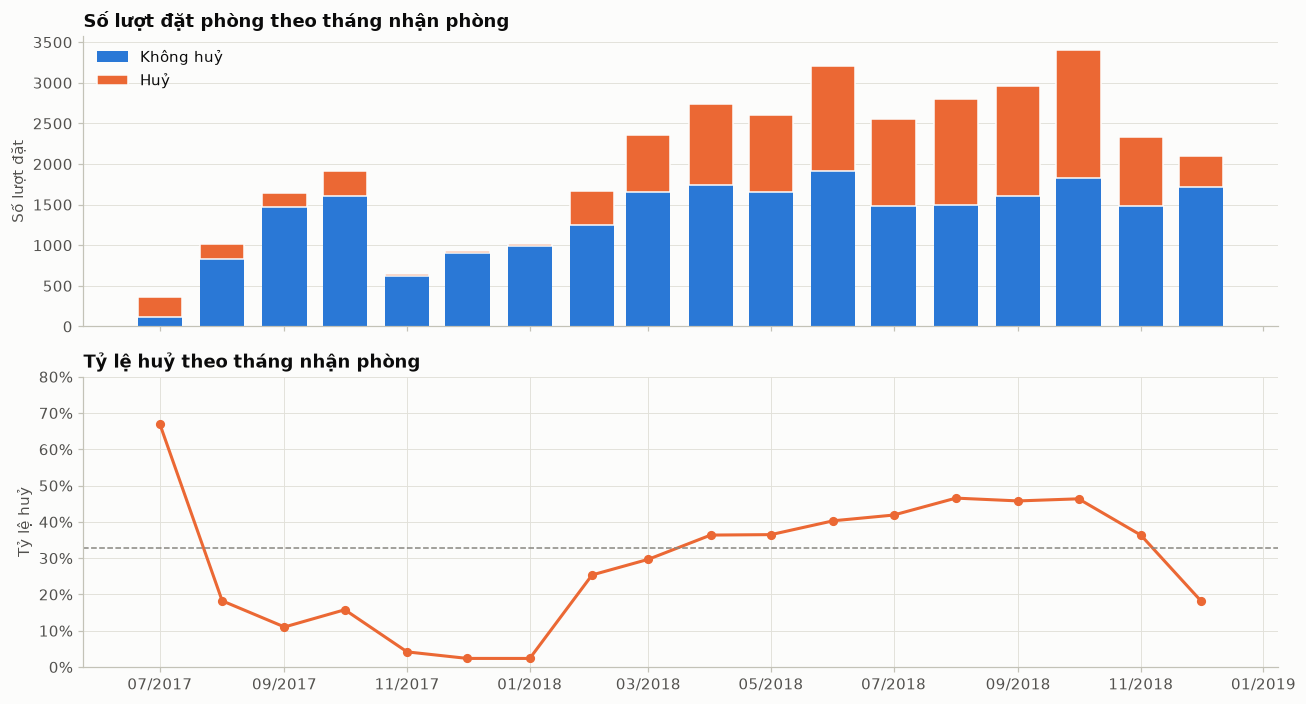

In [16]:
monthly = pd.crosstab(df["arrival"].dt.to_period("M"), df["booking_status"])
monthly_rate = monthly["Canceled"] / monthly.sum(axis=1)
x = monthly.index.to_timestamp()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
ax1.bar(x, monthly["Not_Canceled"], width=22, color=BLUE, label=STATUS_LABELS["Not_Canceled"])
ax1.bar(x, monthly["Canceled"], width=22, bottom=monthly["Not_Canceled"], color=ORANGE,
        label=STATUS_LABELS["Canceled"], edgecolor=SURFACE, linewidth=1)
ax1.set_ylabel("Số lượt đặt")
ax1.legend(loc="upper left")
ax1.grid(axis="x", visible=False)
ax1.set_title("Số lượt đặt phòng theo tháng nhận phòng")

ax2.plot(x, monthly_rate, color=ORANGE, linewidth=2, marker="o", markersize=5)
ax2.axhline(overall_rate, color=MUTED, linestyle="--", linewidth=1)
ax2.set_ylim(0, 0.8)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax2.set_ylabel("Tỷ lệ huỷ")
ax2.set_title("Tỷ lệ huỷ theo tháng nhận phòng")
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
plt.tight_layout()
plt.show()

**Tóm tắt EDA**
- **Lead time là tín hiệu mạnh nhất.** Lead time trung vị của booking bị huỷ là 122 ngày, so với 39 ngày ở booking không huỷ. Tỷ lệ huỷ tăng đều theo lead time: 9% khi đặt trong vòng 7 ngày, 73% khi đặt trước 6–12 tháng, và 95% khi đặt trước hơn 1 năm.
- **Yêu cầu đặc biệt cho thấy mức độ cam kết của khách.** Tỷ lệ huỷ là 43% khi không có yêu cầu nào, 24% với 1 yêu cầu, 15% với 2 yêu cầu, và 0% từ 3 yêu cầu trở lên.
- **Kênh đặt phòng:** *Online* huỷ nhiều nhất (37%), *Corporate* ít (11%), *Complementary* không bao giờ huỷ.
- **Khách quen và khách cần chỗ đậu xe** hiếm khi huỷ (lần lượt 2% và 10%).
- **Giá phòng:** booking bị huỷ có giá cao hơn một chút (trung vị 108€ so với 95€). Giá cao thường rơi vào mùa cao điểm, khi khách đặt sớm và dễ đổi kế hoạch.
- **Theo thời gian:** tỷ lệ huỷ năm 2018 (36,7%) cao gấp khoảng 2,5 lần năm 2017 (14,8%). Thấp nhất là giai đoạn 11/2017–01/2018 (2–4%), cao nhất là 08–10/2018 (khoảng 46%). Tháng 07/2017 có tỷ lệ huỷ 67% nhưng mẫu nhỏ (363 booking, là tháng đầu tiên trong dữ liệu).
- Gói *Meal Plan 2* (46%) và phòng *Loại 6* (42%) có tỷ lệ huỷ cao hơn mức chung, còn các loại phòng khác khá đồng đều.

## 4. Tạo đặc trưng

Ngoài các cột gốc (bỏ `Booking_ID`), tạo thêm một số đặc trưng có ý nghĩa nghiệp vụ:

| Đặc trưng mới | Cách tính | Ý nghĩa |
|---|---|---|
| `arrival_weekday` | thứ trong tuần của ngày nhận phòng | khách công tác (giữa tuần) và khách du lịch (cuối tuần) có hành vi khác nhau |
| `arrival_dayofyear` | ngày thứ mấy trong năm | mùa vụ chi tiết hơn tháng |
| `booking_month`, `booking_weekday` | ngày nhận phòng − `lead_time` | thời điểm khách thực sự đặt phòng |
| `total_nights` | đêm cuối tuần + đêm trong tuần | độ dài kỳ lưu trú |
| `total_guests` | người lớn + trẻ em | quy mô nhóm khách |
| `price_per_guest` | giá phòng / tổng số khách | mức chi tiêu theo đầu người |
| `total_cost` | giá phòng × tổng số đêm | tổng giá trị booking |

Mọi đặc trưng đều tính được ngay khi khách đặt phòng, nên không rò rỉ thông tin từ tương lai.

In [17]:
CAT_COLS = ["type_of_meal_plan", "room_type_reserved", "market_segment_type"]


def add_features(data: pd.DataFrame) -> pd.DataFrame:
    """Thêm đặc trưng dẫn xuất từ các cột gốc (áp dụng được cho booking mới)."""
    X = data.copy()
    arrival = pd.to_datetime(dict(year=X["arrival_year"], month=X["arrival_month"], day=X["arrival_date"]))
    booking = arrival - pd.to_timedelta(X["lead_time"], unit="D")
    X["arrival_weekday"] = arrival.dt.weekday  # 0 = thứ Hai
    X["arrival_dayofyear"] = arrival.dt.dayofyear
    X["booking_month"] = booking.dt.month
    X["booking_weekday"] = booking.dt.weekday
    X["total_nights"] = X["no_of_weekend_nights"] + X["no_of_week_nights"]
    X["total_guests"] = X["no_of_adults"] + X["no_of_children"]
    X["price_per_guest"] = X["avg_price_per_room"] / X["total_guests"]
    X["total_cost"] = X["avg_price_per_room"] * X["total_nights"]
    return X


X = add_features(df[FEATURE_COLS])
y = df["booking_status"].eq("Canceled").astype(int)  # 1 = huỷ
NUM_COLS = X.columns.drop(CAT_COLS).tolist()
print(f"{X.shape[1]} đặc trưng: {len(CAT_COLS)} phân loại + {len(NUM_COLS)} số")

25 đặc trưng: 3 phân loại + 22 số


## 5. Chiến lược đánh giá: xử lý dòng trùng lặp

Mục 2 cho thấy hơn 1/4 số dòng có bản sao giống hệt về mọi đặc trưng. Nếu chia train/test **ngẫu nhiên**, bản gốc nằm ở tập train còn bản sao nằm ở tập test. Khi đó mô hình (nhất là mô hình cây sâu) chỉ cần "nhớ" là đoán đúng. Điểm số vì thế phản ánh khả năng ghi nhớ chứ không phải khả năng dự đoán booking mới.

**Cách xử lý:** gán cho mỗi nhóm dòng giống hệt nhau một mã nhóm (`group`), rồi dùng `StratifiedGroupKFold`. Mỗi nhóm nằm trọn trong train hoặc trọn trong test, đồng thời tỷ lệ huỷ ở hai tập vẫn được giữ cân bằng. Dữ liệu vẫn được giữ nguyên, không xoá dòng nào, vì các dòng trùng nhiều khả năng là những phòng đặt cùng lúc của một đoàn khách.

Chia 80% train (dùng cho cross-validation và tinh chỉnh) và 20% test (chỉ dùng một lần ở cuối).

In [18]:
groups = pd.util.hash_pandas_object(df[FEATURE_COLS], index=False).to_numpy()
print(f"{len(groups):,} dòng → {pd.Series(groups).nunique():,} nhóm đặc trưng khác nhau")

outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(outer_cv.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups[train_idx]

shared = np.intersect1d(groups[train_idx], groups[test_idx]).size
print(f"Train: {len(X_train):,} dòng | Test: {len(X_test):,} dòng | Nhóm xuất hiện ở cả hai tập: {shared}")
print(f"Tỷ lệ huỷ: train {y_train.mean():.1%}, test {y_test.mean():.1%}")

36,238 dòng → 25,832 nhóm đặc trưng khác nhau


Train: 28,990 dòng | Test: 7,248 dòng | Nhóm xuất hiện ở cả hai tập: 0
Tỷ lệ huỷ: train 32.8%, test 32.8%


In [19]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = ["accuracy", "f1", "roc_auc"]


def build_pipeline(model, scale=False):
    """One-hot cho biến phân loại; chuẩn hoá biến số nếu là mô hình tuyến tính."""
    pre = ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
         ("num", StandardScaler() if scale else "passthrough", NUM_COLS)],
        verbose_feature_names_out=False,
    )
    return Pipeline([("pre", pre), ("model", model)])


def cv_scores(pipe, splitter, groups=None):
    res = cross_validate(pipe, X_train, y_train, cv=splitter, groups=groups, scoring=SCORING)
    return ({m: res[f"test_{m}"].mean() for m in SCORING}
            | {"roc_auc_std": res["test_roc_auc"].std(), "fit_time_s": res["fit_time"].mean()})

Cùng một mô hình XGBoost, so sánh hai cách chia fold trên tập train:

In [20]:
xgb_default = XGBClassifier(n_estimators=600, learning_rate=0.05, max_depth=7, subsample=0.8,
                            colsample_bytree=0.8, n_jobs=-1, random_state=RANDOM_STATE)
leak_demo = pd.DataFrame({
    "Chia ngẫu nhiên (StratifiedKFold)":
        cv_scores(build_pipeline(xgb_default), StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)),
    "Chia theo nhóm (StratifiedGroupKFold)":
        cv_scores(build_pipeline(xgb_default), cv, groups_train),
}).T[SCORING]
leak_demo.round(4)

,accuracy,f1,roc_auc
Chia ngẫu nhiên (StratifiedKFold),0.8998,0.8418,0.9576
Chia theo nhóm (StratifiedGroupKFold),0.8557,0.7682,0.9281


**Cùng một mô hình, chia ngẫu nhiên cho accuracy 0,900 và ROC-AUC 0,958, còn chia theo nhóm chỉ còn 0,856 và 0,928.** Khoảng chênh 4,4 điểm accuracy là phần mô hình "học thuộc" các bản sao chứ không phải học được quy luật. Đây là lý do nhiều notebook trên Kaggle báo accuracy khoảng 90%. Từ đây trở đi, mọi đánh giá đều dùng cách chia theo nhóm.

## 6. So sánh mô hình (5-fold StratifiedGroupKFold trên tập train)

In [21]:
models = {
    "Logistic Regression": build_pipeline(LogisticRegression(max_iter=3000), scale=True),
    "Random Forest": build_pipeline(RandomForestClassifier(n_estimators=400, n_jobs=-1, random_state=RANDOM_STATE)),
    "XGBoost": build_pipeline(xgb_default),
    "LightGBM": build_pipeline(LGBMClassifier(n_estimators=600, learning_rate=0.05, num_leaves=63, subsample=0.8,
                                              subsample_freq=1, colsample_bytree=0.8, verbose=-1,
                                              random_state=RANDOM_STATE)),
}
cv_table = pd.DataFrame({name: cv_scores(pipe, cv, groups_train) for name, pipe in models.items()}).T
cv_table = cv_table.sort_values("roc_auc", ascending=False)
cv_table.round(4)

,accuracy,f1,roc_auc,roc_auc_std,fit_time_s
LightGBM,0.8571,0.7698,0.9284,0.0083,5.0211
XGBoost,0.8557,0.7682,0.9281,0.0074,1.2957
Random Forest,0.8546,0.7600,0.9186,0.0095,1.5632
Logistic Regression,0.8070,0.6821,0.8649,0.0138,0.0787


**Nhận xét.** Ba mô hình dạng cây vượt xa Logistic Regression (ROC-AUC khoảng 0,93 so với 0,86). Lý do là quan hệ giữa các đặc trưng và khả năng huỷ phòng là phi tuyến và có tương tác, ví dụ ảnh hưởng của lead time thay đổi theo mùa và theo kênh. LightGBM và XGBoost gần như bằng nhau: ROC-AUC chỉ chênh 0,0003, nhỏ hơn rất nhiều so với mức dao động giữa các fold (khoảng 0,008). **Chọn XGBoost** vì huấn luyện nhanh hơn khoảng 4 lần (1,3 giây so với 5,0 giây mỗi fold).

## 7. Tinh chỉnh siêu tham số XGBoost

Dùng `RandomizedSearchCV` (20 tổ hợp × 5 fold theo nhóm), tối ưu theo **ROC-AUC**. Chỉ số này không phụ thuộc ngưỡng phân loại, ngưỡng sẽ được chọn riêng ở mục 8. Cấu hình mặc định ở mục 6 cũng được đưa vào so sánh: mô hình cuối cùng là cấu hình có ROC-AUC (CV) cao hơn.

In [22]:
param_dist = {
    "model__n_estimators": randint(400, 1500),
    "model__learning_rate": loguniform(0.02, 0.1),
    "model__max_depth": randint(6, 13),
    "model__min_child_weight": randint(1, 6),
    "model__subsample": uniform(0.7, 0.3),
    "model__colsample_bytree": uniform(0.5, 0.5),
    "model__gamma": uniform(0, 0.3),
    "model__reg_lambda": loguniform(0.5, 5),
}
search = RandomizedSearchCV(
    build_pipeline(XGBClassifier(n_jobs=-1, random_state=RANDOM_STATE)),
    param_distributions=param_dist, n_iter=20, scoring="roc_auc", cv=cv,
    random_state=RANDOM_STATE, n_jobs=1,
)
search.fit(X_train, y_train, groups=groups_train)

default_auc, fold_std = cv_table.loc["XGBoost", ["roc_auc", "roc_auc_std"]]
print(f"ROC-AUC (CV) cấu hình mặc định  : {default_auc:.4f}  (độ lệch chuẩn giữa các fold: {fold_std:.4f})")
print(f"ROC-AUC (CV) tốt nhất khi tìm kiếm: {search.best_score_:.4f}")

if search.best_score_ > default_auc:
    best_model, chosen = search.best_estimator_, "XGBoost đã tinh chỉnh"
else:
    best_model, chosen = build_pipeline(xgb_default).fit(X_train, y_train), "XGBoost cấu hình mặc định"
print(f"→ Mô hình cuối cùng: {chosen}")

pd.Series({k.removeprefix("model__"): v for k, v in search.best_params_.items()},
          name="tham số tốt nhất khi tìm kiếm").to_frame()

ROC-AUC (CV) cấu hình mặc định  : 0.9281  (độ lệch chuẩn giữa các fold: 0.0074)
ROC-AUC (CV) tốt nhất khi tìm kiếm: 0.9262


→ Mô hình cuối cùng: XGBoost cấu hình mặc định


,tham số tốt nhất khi tìm kiếm
colsample_bytree,0.593285
gamma,0.267768
learning_rate,0.047645
max_depth,7.000000
min_child_weight,4.000000
n_estimators,589.000000
reg_lambda,0.644202
subsample,0.768381


**Tinh chỉnh không cải thiện được mô hình.** Tổ hợp tốt nhất trong 20 lần thử đạt ROC-AUC 0,926, thấp hơn một chút so với cấu hình mặc định (0,928). Mức chênh này nhỏ hơn nhiều so với độ lệch chuẩn giữa các fold (0,007). Cấu hình ban đầu (600 cây, learning rate 0,05, độ sâu 7, lấy mẫu 80% dòng và 80% cột) vốn đã nằm gần vùng tối ưu, nên mô hình cuối cùng giữ nguyên cấu hình này. Với bộ dữ liệu này, muốn cải thiện tiếp thì nên đầu tư vào dữ liệu và đặc trưng (ví dụ lịch sử của khách, thông tin đoàn) hơn là vào siêu tham số.

## 8. Chọn ngưỡng phân loại

Mặc định mô hình dự đoán "huỷ" khi xác suất ≥ 0,5. Ngưỡng này không nhất thiết tối ưu: hạ ngưỡng thì bắt được nhiều booking huỷ hơn (recall tăng) nhưng báo nhầm nhiều hơn (precision giảm). Ngưỡng được chọn trên **dự đoán out-of-fold của tập train** để tập test vẫn hoàn toàn độc lập. Ở đây chọn ngưỡng tối đa hoá F1. Trong thực tế nên chọn theo chi phí: mất bao nhiêu khi bỏ trống một phòng so với khi bán vượt nhầm.

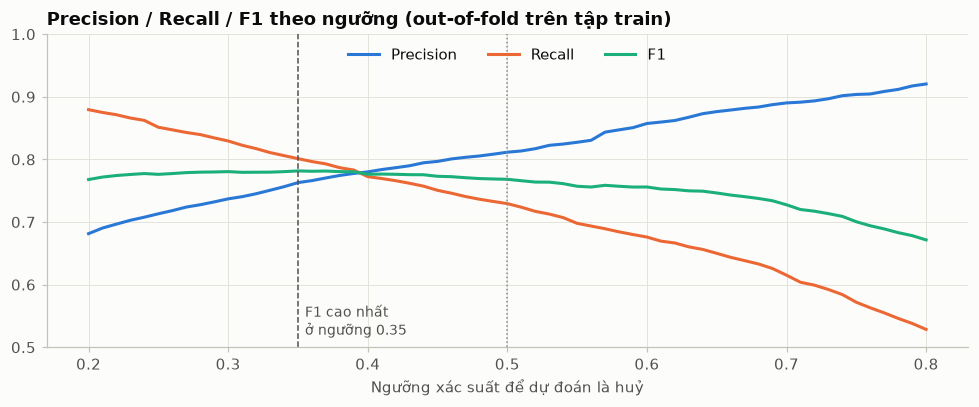

,precision,recall,f1,accuracy
threshold,,,,
0.50,0.8115,0.7293,0.7682,0.8557
0.35,0.7629,0.8012,0.7816,0.8532


In [23]:
oof_proba = cross_val_predict(best_model, X_train, y_train, cv=cv, groups=groups_train,
                              method="predict_proba")[:, 1]

thresholds = np.round(np.arange(0.20, 0.801, 0.01), 2)
threshold_table = pd.DataFrame({
    "precision": [precision_score(y_train, oof_proba >= t) for t in thresholds],
    "recall": [recall_score(y_train, oof_proba >= t) for t in thresholds],
    "f1": [f1_score(y_train, oof_proba >= t) for t in thresholds],
    "accuracy": [accuracy_score(y_train, oof_proba >= t) for t in thresholds],
}, index=pd.Index(thresholds, name="threshold"))
best_threshold = threshold_table["f1"].idxmax()

fig, ax = plt.subplots(figsize=(9, 3.8))
for col, color, label in [("precision", BLUE, "Precision"), ("recall", ORANGE, "Recall"), ("f1", AQUA, "F1")]:
    ax.plot(threshold_table.index, threshold_table[col], color=color, linewidth=2, label=label)
ax.axvline(0.5, color=MUTED, linestyle=":", linewidth=1)
ax.axvline(best_threshold, color=INK_2, linestyle="--", linewidth=1)
ax.text(best_threshold + 0.005, 0.52, f"F1 cao nhất\nở ngưỡng {best_threshold:.2f}", color=INK_2, fontsize=9)
ax.set_ylim(0.5, 1)
ax.set_xlabel("Ngưỡng xác suất để dự đoán là huỷ")
ax.legend(loc="upper center", ncol=3)
ax.set_title("Precision / Recall / F1 theo ngưỡng (out-of-fold trên tập train)")
plt.tight_layout()
plt.show()

threshold_table.loc[[0.5, best_threshold]].round(4)

## 9. Đánh giá trên tập test

Mô hình cuối cùng (chọn ở mục 7) đã được fit trên toàn bộ tập train. Đây là lần duy nhất tập test được sử dụng.

In [24]:
test_proba = best_model.predict_proba(X_test)[:, 1]


def summarize(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    return {"accuracy": accuracy_score(y_true, pred), "precision": precision_score(y_true, pred),
            "recall": recall_score(y_true, pred), "f1": f1_score(y_true, pred),
            "roc_auc": roc_auc_score(y_true, proba)}


test_table = pd.DataFrame({
    "Ngưỡng 0.50": summarize(y_test, test_proba, 0.5),
    f"Ngưỡng {best_threshold:.2f} (tối ưu F1)": summarize(y_test, test_proba, best_threshold),
}).T
test_table.round(4)

,accuracy,precision,recall,f1,roc_auc
Ngưỡng 0.50,0.8688,0.8230,0.7638,0.7923,0.93
Ngưỡng 0.35 (tối ưu F1),0.8478,0.7398,0.8261,0.7806,0.93


In [25]:
y_pred = (test_proba >= best_threshold).astype(int)
print(f"Classification report trên tập test (ngưỡng {best_threshold:.2f}):\n")
print(classification_report(y_test, y_pred, target_names=["Không huỷ", "Huỷ"], digits=3))

Classification report trên tập test (ngưỡng 0.35):

              precision    recall  f1-score   support

   Không huỷ      0.910     0.858     0.884      4873
         Huỷ      0.740     0.826     0.781      2375

    accuracy                          0.848      7248
   macro avg      0.825     0.842     0.832      7248
weighted avg      0.854     0.848     0.850      7248



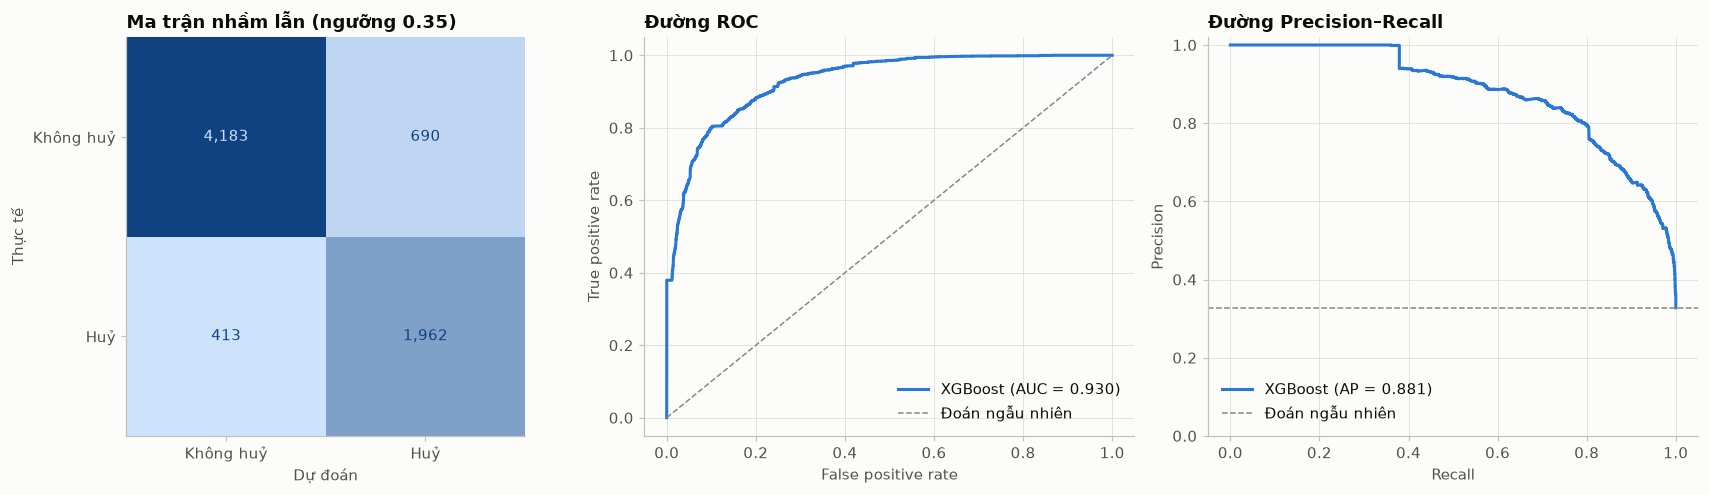

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Không huỷ", "Huỷ"],
                                        cmap=SEQ_BLUE, colorbar=False, values_format=",", ax=axes[0])
axes[0].grid(False)
axes[0].set_xlabel("Dự đoán")
axes[0].set_ylabel("Thực tế")
axes[0].set_title(f"Ma trận nhầm lẫn (ngưỡng {best_threshold:.2f})")

fpr, tpr, _ = roc_curve(y_test, test_proba)
axes[1].plot(fpr, tpr, color=BLUE, linewidth=2, label=f"XGBoost (AUC = {roc_auc_score(y_test, test_proba):.3f})")
axes[1].plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1, label="Đoán ngẫu nhiên")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].legend(loc="lower right")
axes[1].set_title("Đường ROC")

prec, rec, _ = precision_recall_curve(y_test, test_proba)
axes[2].plot(rec, prec, color=BLUE, linewidth=2, label=f"XGBoost (AP = {average_precision_score(y_test, test_proba):.3f})")
axes[2].axhline(y_test.mean(), color=MUTED, linestyle="--", linewidth=1, label="Đoán ngẫu nhiên")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].set_ylim(0, 1.02)
axes[2].legend(loc="lower left")
axes[2].set_title("Đường Precision–Recall")

plt.tight_layout()
plt.show()

**Kết quả trên tập test**
- **ROC-AUC 0,930 và Average Precision 0,881.** Kết quả khớp với cross-validation (0,928 ± 0,007), tức mô hình không bị overfit và con số này phản ánh đúng hiệu năng trên booking mới.
- **Ngưỡng 0,5:** accuracy 86,9%. Trong các booking bị dự đoán là huỷ, 82,3% huỷ thật (precision). Mô hình bắt được 76,4% số booking huỷ thật (recall).
- **Ngưỡng 0,35:** bắt được 82,6% số booking huỷ (1.962/2.375). Đổi lại, precision giảm còn 74,0% và accuracy còn 84,8%.
- Ngưỡng 0,35 cho F1 cao nhất trên dữ liệu train (out-of-fold), nhưng trên tập test F1 ở ngưỡng 0,5 lại nhỉnh hơn (0,792 so với 0,781). Đường F1 gần như phẳng trong khoảng 0,35–0,5 (xem biểu đồ ở mục 8), nên **việc chọn ngưỡng là quyết định kinh doanh, không phải kỹ thuật**:
  - Nếu bỏ sót một booking huỷ (để phòng trống) tốn kém hơn báo nhầm (chỉ phải nhắc khách hoặc yêu cầu cọc), nên dùng ngưỡng thấp.
  - Nếu dùng dự đoán để bán vượt phòng, báo nhầm nghĩa là khách đến mà không còn phòng, khi đó nên dùng ngưỡng cao hơn.

## 10. Mức độ quan trọng của đặc trưng

Dùng **permutation importance** trên tập test: xáo trộn ngẫu nhiên từng cột rồi đo ROC-AUC giảm bao nhiêu. Khác với feature importance có sẵn của mô hình cây, cách này đo trực tiếp mức đóng góp vào chất lượng dự đoán trên dữ liệu mới, và không bị thiên lệch về các biến có nhiều giá trị.

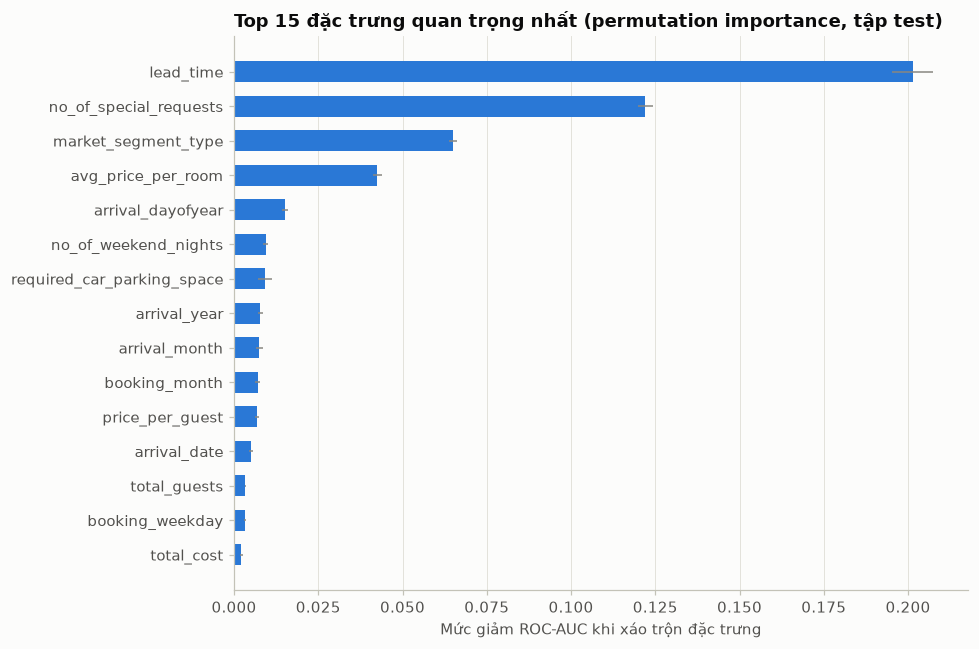

In [27]:
perm = permutation_importance(best_model, X_test, y_test, scoring="roc_auc", n_repeats=5,
                              random_state=RANDOM_STATE)
importance = (pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std}, index=X_test.columns)
              .sort_values("mean", ascending=False))
top = importance.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top["mean"], xerr=top["std"], color=BLUE, height=0.6,
        error_kw={"ecolor": MUTED, "elinewidth": 1, "capsize": 0})
ax.set_xlabel("Mức giảm ROC-AUC khi xáo trộn đặc trưng")
ax.grid(axis="y", visible=False)
ax.set_title("Top 15 đặc trưng quan trọng nhất (permutation importance, tập test)")
plt.tight_layout()
plt.show()

**Nhận xét.** Bốn đặc trưng tạo ra phần lớn khả năng dự đoán, khớp với những gì EDA đã cho thấy:
1. **`lead_time`:** xáo trộn cột này làm ROC-AUC giảm khoảng 0,20. Đây là đặc trưng quan trọng nhất.
2. **`no_of_special_requests`** (≈ 0,12): khách có yêu cầu cụ thể thường là khách có ý định đến ở thật.
3. **`market_segment_type`** (≈ 0,065): kênh Online rủi ro hơn hẳn Corporate và Complementary.
4. **`avg_price_per_room`** (≈ 0,04).

Tiếp theo là nhóm đặc trưng **mùa vụ** (`arrival_dayofyear`, `arrival_month`, `booking_month`, `arrival_year`), số đêm cuối tuần và nhu cầu chỗ đậu xe. Một số đặc trưng tự tạo (`arrival_dayofyear`, `booking_month`, `price_per_guest`) có đóng góp, nhưng nhỏ hơn nhiều so với bốn đặc trưng chính.

## 11. Kết luận & khuyến nghị

**Kết quả mô hình**
- Mô hình cuối cùng là **XGBoost** (600 cây, độ sâu 7) với 25 đặc trưng (17 cột gốc và 8 đặc trưng tự tạo).
- Trên tập test độc lập, mô hình đạt **ROC-AUC 0,930**. Ở ngưỡng 0,5, accuracy là **86,9%**. Nếu dùng ngưỡng 0,35, mô hình **bắt được 82,6% số booking bị huỷ**.
- Accuracy này thấp hơn mức khoảng 90% thường thấy trên Kaggle vì notebook đánh giá theo nhóm, loại bỏ hiệu ứng "học thuộc" các booking trùng lặp (mục 5). Nếu chia ngẫu nhiên, cùng mô hình này cũng đạt khoảng 90%, nhưng con số đó không phản ánh hiệu năng thật trên booking mới.

**Khuyến nghị cho khách sạn**
1. **Siết chính sách với booking đặt rất sớm.** Booking đặt trước hơn 6 tháng có tỷ lệ huỷ trên 70%. Nên yêu cầu đặt cọc và gửi email xác nhận lại khi gần đến ngày nhận phòng.
2. **Khuyến khích khách gửi yêu cầu đặc biệt** ngay khi đặt phòng (chọn tầng, view, giường phụ…). Trong dữ liệu, khách có từ 3 yêu cầu trở lên chưa từng huỷ. *Lưu ý: đây là tương quan, chưa chắc là quan hệ nhân quả. Nên thử nghiệm A/B trước khi áp dụng rộng.*
3. **Chú ý kênh Online** (37% huỷ). Có thể cân nhắc chính sách huỷ chặt hơn, hoặc giá ưu đãi kèm điều kiện không hoàn tiền.
4. **Giữ chân khách quen** (chỉ 2% huỷ) bằng chương trình thành viên.
5. **Dùng xác suất huỷ của mô hình để bán vượt có kiểm soát.** Cộng xác suất huỷ của các booking trong cùng một ngày sẽ ra ước lượng số phòng bị trống, từ đó quyết định số phòng có thể bán thêm.

**Hạn chế & hướng phát triển**
- Dữ liệu chỉ có 18 tháng (07/2017–12/2018) và tỷ lệ huỷ thay đổi mạnh theo thời gian (15% năm 2017 so với 37% năm 2018). Trước khi đưa vào sử dụng thực tế, nên kiểm tra thêm theo trục thời gian (train trên các tháng cũ, test trên các tháng mới hơn) và huấn luyện lại định kỳ.
- `arrival_year` chỉ có hai giá trị (2017, 2018) nên không áp dụng được cho năm mới. Khi triển khai nên bỏ đặc trưng này hoặc thay bằng đặc trưng không phụ thuộc năm.
- Các bước tiếp theo có thể làm: dùng SHAP để giải thích từng dự đoán, hiệu chỉnh xác suất (calibration) trước khi dùng cho bán vượt, và chọn ngưỡng theo chi phí thực tế của khách sạn.